CUSTOMER DATASET
   tenure_months  monthly_fee  support_tickets  late_payments  usage_drop_pct  \
0             39    16.565505                1              2       26.088485   
1             52    47.614147                3              0       17.635031   
2             29    13.105864                0              0       74.023056   
3             15    79.743126                4              0       69.437331   
4             43    76.669498                1              0       39.974658   
5              8   126.392009                3              1        4.907510   
6             21    53.088814                3              1       57.164988   
7             39   124.294003                2              1       49.872939   
8             58   145.516327                1              1       77.644374   
9             19    22.377151                2              3       44.716259   

   churn  
0      1  
1      0  
2      0  
3      1  
4      1  
5      0  
6      0  
7  

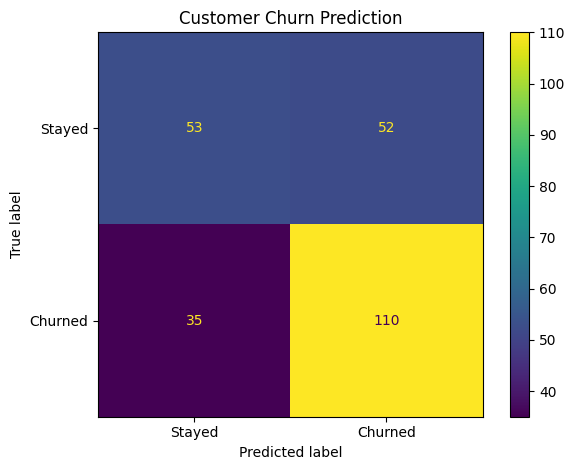


FEATURE IMPORTANCE
monthly_fee        0.337
usage_drop_pct     0.276
tenure_months      0.224
support_tickets    0.093
late_payments      0.071
dtype: float64


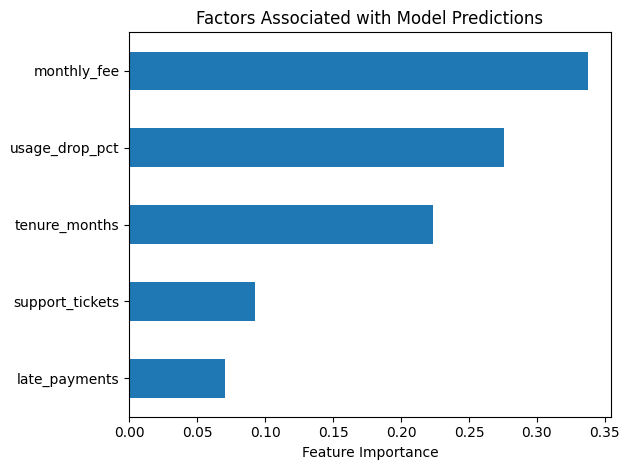


TOP 15 CUSTOMERS BY PREDICTED CHURN RISK
 tenure_months  monthly_fee  support_tickets  late_payments  usage_drop_pct  churn_risk risk_category                     retention_action
            11      108.977                0              1          57.994       1.000     High Risk Personal outreach and service review
             9      148.730                1              1          19.563       1.000     High Risk Personal outreach and service review
            14      148.076                1              2          62.555       0.993     High Risk Personal outreach and service review
            32      112.606                6              1          58.738       0.993     High Risk Personal outreach and service review
            11      118.337                1              3          68.707       0.993     High Risk Personal outreach and service review
            28       91.306                1              1          63.623       0.993     High Risk Personal outreach and 

In [1]:

# PROJECT 2: CUSTOMER CHURN & RETENTION INTELLIGENCE

# STEP 1: IMPORT LIBRARIES

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)

np.random.seed(42)


# STEP 2: CREATE CUSTOMER DATASET

n = 1000

df = pd.DataFrame({
    "tenure_months": np.random.randint(1, 61, n),
    "monthly_fee": np.random.uniform(10, 150, n),
    "support_tickets": np.random.poisson(2, n),
    "late_payments": np.random.poisson(1, n),
    "usage_drop_pct": np.random.uniform(0, 80, n)
})

# Generate illustrative churn probabilities
logit = (
    -2.0
    - 0.035 * df["tenure_months"]
    + 0.018 * df["monthly_fee"]
    + 0.32 * df["support_tickets"]
    + 0.45 * df["late_payments"]
    + 0.025 * df["usage_drop_pct"]
)

probability = 1 / (1 + np.exp(-logit))

# 0 = Stayed, 1 = Churned
df["churn"] = (
    np.random.rand(n) < probability
).astype(int)

print("CUSTOMER DATASET")
print(df.head(10))

print("\nCHURN DISTRIBUTION")
print(df["churn"].value_counts())


# STEP 3: PREPARE DATA

X = df.drop(columns=["churn"])
y = df["churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)


# STEP 4: TRAIN MACHINE LEARNING MODEL

model = RandomForestClassifier(
    n_estimators=150,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train, y_train)

print("\nMODEL TRAINING COMPLETED")


# STEP 5: EVALUATE MODEL

predictions = model.predict(X_test)

probabilities = model.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, predictions)
auc = roc_auc_score(y_test, probabilities)

print("\nMODEL PERFORMANCE")
print("Accuracy:", round(accuracy, 3))
print("ROC-AUC:", round(auc, 3))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    predictions,
    zero_division=0
))


# STEP 6: CONFUSION MATRIX

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    display_labels=["Stayed", "Churned"]
)

plt.title("Customer Churn Prediction")
plt.tight_layout()
plt.show()


# STEP 7: IDENTIFY IMPORTANT FEATURES

importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("\nFEATURE IMPORTANCE")
print(importance.round(3))

importance.sort_values().plot(
    kind="barh",
    title="Factors Associated with Model Predictions"
)

plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()


# STEP 8: PREDICT CUSTOMER CHURN RISK

df["churn_risk"] = model.predict_proba(X)[:, 1]

df["risk_category"] = np.select(
    [
        df["churn_risk"] >= 0.65,
        df["churn_risk"] >= 0.40
    ],
    [
        "High Risk",
        "Medium Risk"
    ],
    default="Low Risk"
)

# Recommend retention actions
df["retention_action"] = np.select(
    [
        df["risk_category"] == "High Risk",
        df["risk_category"] == "Medium Risk"
    ],
    [
        "Personal outreach and service review",
        "Check satisfaction and offer support"
    ],
    default="Continue regular engagement"
)


# STEP 9: DISPLAY HIGH-RISK CUSTOMERS

high_risk_customers = df.sort_values(
    "churn_risk",
    ascending=False
).head(15)

print("\nTOP 15 CUSTOMERS BY PREDICTED CHURN RISK")

print(
    high_risk_customers[
        [
            "tenure_months",
            "monthly_fee",
            "support_tickets",
            "late_payments",
            "usage_drop_pct",
            "churn_risk",
            "risk_category",
            "retention_action"
        ]
    ].round(3).to_string(index=False)
)


# STEP 10: BUSINESS INSIGHTS

print("\nBUSINESS RECOMMENDATIONS")
print("1. Contact customers with high predicted churn risk.")
print("2. Investigate repeated customer support issues.")
print("3. Review late payments and declines in product usage.")
print("4. Test personalized retention offers.")
print("5. Track retention outcomes and model performance.")

print("\nPROJECT COMPLETED SUCCESSFULLY")
print("Note: Synthetic data is used for educational purposes.")
